# Tutorial：Denoising on human prefrontal cortex Slide-tags data

## Outline

1. Import packages
2. Load data
3. Batch effect correction
4. Obtain microenvironment representations for ST data
5. Obtain microenvironment representations for scRNA-seq data
6. Denoising
7. Marker genes visualization

## 1. Import packages

We need to specify the working directory in R.

In [1]:
import scanpy as sc
import os
from pathlib import Path
import cellback as cb
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
os.environ['R_HOME'] = '/home/liujixin/anaconda3/envs/cellback_env/lib/R/'
os.environ['R_USER'] = '/home/liujixin/anaconda3/envs/cellback_env/lib/R/library'

## 2. Load data

Using matched human prefrontal cortex scRNA-seq data, we perform weighted averaging of gene expression from both transcriptionally and environmentally similar scRNA-seq cells of the same cell type as each target ST cell, thereby alleviating sparsity in the Slide-tags data.

In [2]:
#human cortex denoising
#read data
data_dir = Path("../CellBack/data/humancortex/")
slide = sc.read_h5ad(data_dir / "slide_tag.h5ad")
singlecell = sc.read_h5ad(data_dir / "sc_seq.h5ad")
slide.var_names_make_unique()
singlecell.var_names_make_unique()
sc.pp.filter_cells(singlecell, min_genes=200)
sc.pp.filter_genes(singlecell, min_cells=3)

common_gene = slide.var_names.intersection(singlecell.var_names)
slide = slide[:, common_gene]
singlecell = singlecell[:, common_gene]

#Since the Slide-tags data has been normalized, we just normalize scRNA-seq data.
sc.pp.normalize_total(singlecell, target_sum=1e4)
sc.pp.log1p(singlecell)

## 3. Batch effect correction

We use scANVI method to obtain low-dimensional embeddings for the two datasets.

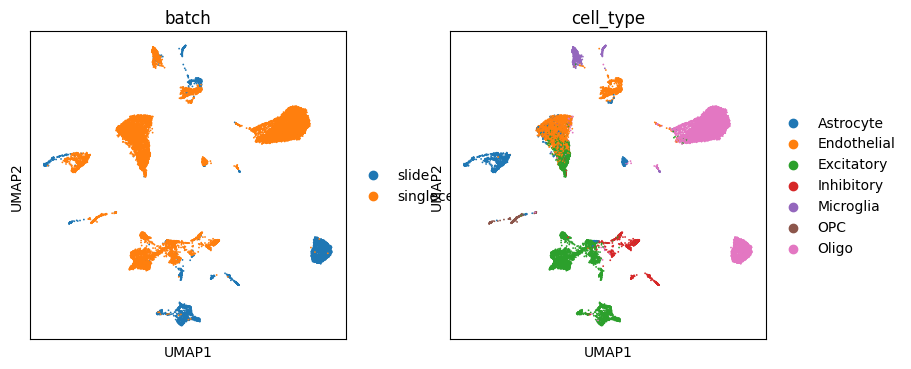

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
You are using a CUDA device ('NVIDIA A100-PCIE-40GB') that has Tensor Cores. To properly utilize them, you should set `torch.set_float32_matmul_precision('medium' | 'high')` which will trade-off precision for performance. For more details, read https://pytorch.org/docs/stable/generated/torch.set_float32_matmul_precision.html#torch.set_float32_matmul_precision
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Epoch 400/400: 100%|██████████| 400/400 [06:05<00:00,  1.12it/s, v_num=1, train_loss_step=267, train_loss_epoch=240]

`Trainer.fit` stopped: `max_epochs=400` reached.


Epoch 400/400: 100%|██████████| 400/400 [06:05<00:00,  1.10it/s, v_num=1, train_loss_step=267, train_loss_epoch=240]


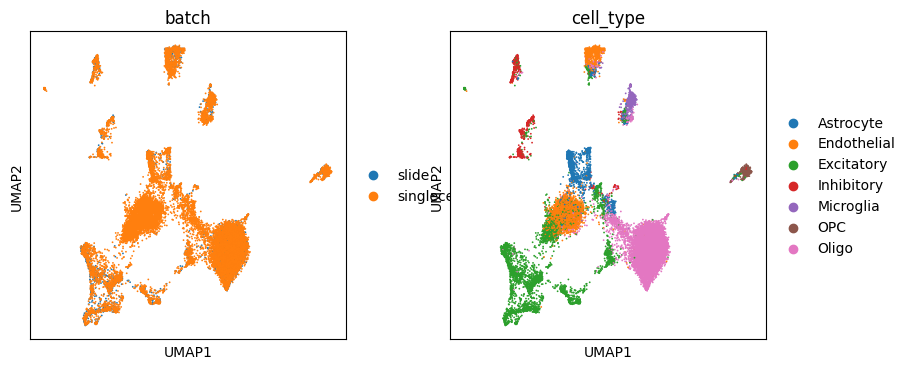

INFO     Training for 20 epochs.                                                                                   


GPU available: True (cuda), used: True
TPU available: False, using: 0 TPU cores
IPU available: False, using: 0 IPUs
HPU available: False, using: 0 HPUs
LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


Epoch 20/20: 100%|██████████| 20/20 [00:48<00:00,  2.41s/it, v_num=1, train_loss_step=235, train_loss_epoch=216]

`Trainer.fit` stopped: `max_epochs=20` reached.


Epoch 20/20: 100%|██████████| 20/20 [00:48<00:00,  2.40s/it, v_num=1, train_loss_step=235, train_loss_epoch=216]


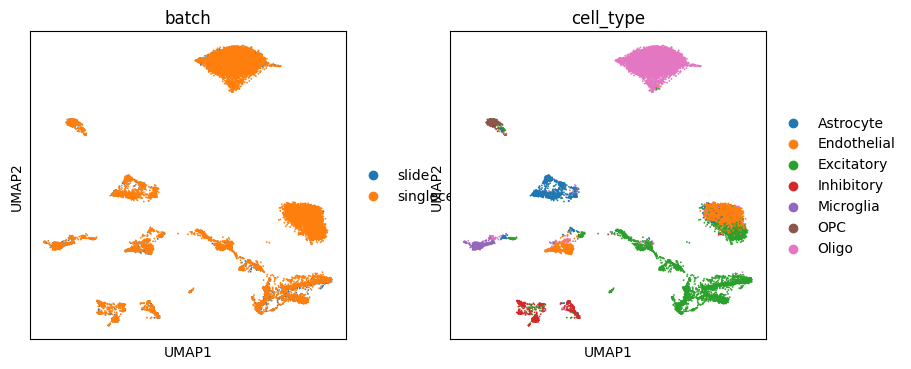

In [3]:
plt.rcParams["figure.figsize"] = (4, 4)
#remove batch effect
adata_sc, adata_sp = cb.utils.run_scvi(slide, singlecell)

We reconstruct the gene expression matrices of HVGs using Seurat to ensure that the feature dimensions are comparable.

In [4]:
#reconstruct expression matrices of HVGs
dictory_sc = "../CellBack/test/sc/"
dictory_st = "../CellBack/test/st/"
dictory_matrix = "../CellBack/test/"

adata_sc_re, adata_sp_re = cb.utils.run_seurat(adata_sp, adata_sc, dictory_sc= dictory_sc, dictory_st= dictory_st, dictory_matrix= dictory_matrix)


    an issue that caused a segfault when used with rpy2:
    https://github.com/rstudio/reticulate/pull/1188
    Make sure that you use a version of that package that includes
    the fix.
    [1] 4 4 0



R[write to console]: Centering and scaling data matrix

  |                                                                            
  |                                                                      |   0%
  |                                                                            
  |===================================                                   |  50%
  |                                                                            
  |======================================================================| 100%
R[write to console]: 

R[write to console]: PC_ 1 
Positive:  INPP5D, ST6GAL1, LRMDA, SLCO2B1, PITPNC1, CHST11, FLT1, FLI1, NRXN1, NRG3 
	   EPAS1, NXN, SLC7A5, ADAMTS9, PALD1, COBLL1, PIK3R3, ZFP36L1, SYT1, THSD4 
	   FAM155A, VWF, PECAM1, CLU, HLA-B, SP100, TGFBR2, IL4R, ITGA6, ATP10A 
Negative:  ST18, IL1RAPL1, RNF220, TMEM144, PIP4K2A, PLP1, CTNNA3, TF, SLC7A14-AS1, ENPP2 
	   TMTC2, ZNF536, C10orf90, KCNH8, CLMN, DOCK5, CLDN11, FRMD4B, DOCK10, MOG 
	   NC

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 18232
Number of edges: 904326

Running Louvain algorithm...


R[write to console]: 0%   10   20   30   40   50   60   70   80   90   100%

R[write to console]: [----|----|----|----|----|----|----|----|----|----|

R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: 

Maximum modularity in 10 random starts: 0.9295
Number of communities: 18
Elapsed time: 2 seconds


...

R[write to console]: Warning:
R[write to console]:  Layer counts isn't present in the assay object; returning NULL

R[write to console]: Centering and scaling data matrix

  |                                                                            
  |                                                                      |   0%
  |                                                                            
  |===================================                                   |  50%
  |                                                                            
  |======================================================================| 100%
R[write to console]: 

R[write to console]: PC_ 1 
Positive:  CLU, FLT1, TMSB4X, FLI1, CHST11, INPP5D, ITGA6, PITPNC1, VWF, CST3 
	   ADAMTS9, SLCO2B1, LRMDA, ST6GAL1, NXN, HLA-B, HLA-E, PIK3R3, EPAS1, CLDN5 
	   PDGFB, THSD4, IL4R, ATP10A, IFITM3, CALM1, SLC7A5, NRG3, GFAP, IFI27 
Negative:  ST18, IL1RAPL1, CTNNA3, RNF220, PLP1, PIP4K2A, TMEM144

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 18232
Number of edges: 939071

Running Louvain algorithm...


R[write to console]: 0%   10   20   30   40   50   60   70   80   90   100%

R[write to console]: [----|----|----|----|----|----|----|----|----|----|

R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: 

Maximum modularity in 10 random starts: 0.9259
Number of communities: 19
Elapsed time: 3 seconds


R[write to console]: 12:14:01 UMAP embedding parameters a = 0.9922 b = 1.112

R[write to console]: 12:14:01 Read 18232 rows and found 50 numeric columns

R[write to console]: 12:14:01 Using Annoy for neighbor search, n_neighbors = 30

R[write to console]: 12:14:01 Building Annoy index with metric = cosine, n_trees = 50

R[write to console]: 0%   10   20   30   40   50   60   70   80   90   100%

R[write to console]: [----|----|----|----|----|----|----|----|----|----|

R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: *
R[write to console]: 

## 4. Obtain microenvironment representations for ST data

We use BANKSY method to obtain the microenvironment representations for the ST data. lambda_list = [0.8] indicates that the weights of intrinsic expression versus microenvironment expression are 0.2 and 0.8, respectively.

In [5]:
#run BANKSY
lambda_list = [0.8]
adata_sp_micro, micro_weight = cb.utils.run_banksy(adata_sp_re, lambda_list=lambda_list)


Median distance to closest cell = 32.41067371636311

---- Ran median_dist_to_nearest_neighbour in 0.01 s ----


Median distance to closest cell = 32.4107

---- Ran generate_spatial_distance_graph in 0.02 s ----

---- Ran row_normalize in 0.01 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.13 s ----

---- Ran generate_spatial_distance_graph in 0.03 s ----

---- Ran theta_from_spatial_graph in 0.04 s ----

---- Ran row_normalize in 0.01 s ----

---- Ran generate_spatial_weights_fixed_nbrs in 0.19 s ----

Runtime Jan-14-2026-12-15

2000 genes to be analysed:
Gene List:
Index(['AL645608.2', 'AL391244.1', 'AL109917.1', 'TP73', 'SMIM1', 'AL359881.2',
       'AL359881.1', 'SLC2A5', 'PIK3CD-AS2', 'AL357140.2',
       ...
       'MT-CO1', 'MT-CO2', 'MT-ATP6', 'MT-CO3', 'MT-ND3', 'MT-ND4', 'MT-ND5',
       'MT-ND6', 'MT-CYB', 'AC145212.1'],
      dtype='object', length=2000)

Decay Type: scaled_gaussian
Weights Object: {'weights': {0: <4067x4067 sparse matrix of type '<class 'numpy.f

## 5. Obtain microenvironment representations for scRNA-seq data

Edges between spatial cells are controlled by parameter threshold_distance, while edges between spatial cells and single cells are based on the similarity in low-dimensional embeddings obtained from scANVI, which are stored in .obsm['X_scANVI'], with k representing the number of most similar single cells connected to each spatial cell. Then, we obtain the microenvironment representations for scRNA-seq data through a multi-head graph attention network to adaptively propagate microenvironmental information from ST data.

In [6]:
#model training
#construct graphs
edge_index_intra = cb.utils.intra_spatial_proximity(adata_sp_re,
                                                          threshold_distance=110)
edge_index_inter = cb.utils.inter_correlation_calculation(adata_sc_re,
                                                                adata_sp_re, basis='X_scANVI', k=3)
edge_index = edge_index_intra + edge_index_inter

lam = micro_weight
features, targets = cb.utils.extra_features(adata_sc_re,
                                            adata_sp_re,
                                            adata_sp_micro, lam=lam)

100%|██████████| 4067/4067 [02:21<00:00, 28.66it/s]


Mean degree(neighbors): 4.160437669043521


100%|██████████| 14165/14165 [55:55<00:00,  4.22it/s]


In [7]:
#microenvironment representations learning
celltype_list = adata_sc_re.obs['cell_type'].unique()
cb.micro_network_training(adata_sc=adata_sc_re,
                          adata_sp=adata_sp_re,
                          edge_index=edge_index,
                          features=features,
                          targets=targets,
                          cell_types=celltype_list,
                          epoch=30000)

Epoch 0, Loss: 4.2256
Epoch 1000, Loss: 1.1193
Epoch 2000, Loss: 0.9642
Epoch 3000, Loss: 0.8199
Epoch 4000, Loss: 0.8031
Epoch 5000, Loss: 0.7129
Epoch 6000, Loss: 0.6934
Epoch 7000, Loss: 0.6801
Epoch 8000, Loss: 0.6663
Epoch 9000, Loss: 0.6670
Epoch 10000, Loss: 0.6589
Epoch 11000, Loss: 0.6553
Epoch 12000, Loss: 0.6199
Epoch 13000, Loss: 0.6172
Epoch 14000, Loss: 0.6155
Epoch 15000, Loss: 0.6064
Epoch 16000, Loss: 0.6197
Epoch 17000, Loss: 0.6131
Epoch 18000, Loss: 0.6399
Epoch 19000, Loss: 0.5827
Epoch 20000, Loss: 0.5821
Epoch 21000, Loss: 0.5928
Epoch 22000, Loss: 0.5934
Epoch 23000, Loss: 0.6053
Epoch 24000, Loss: 0.5892
Epoch 25000, Loss: 0.5966
Epoch 26000, Loss: 0.5704
Epoch 27000, Loss: 0.5729
Epoch 28000, Loss: 0.5706
Epoch 29000, Loss: 0.5714


## 6. Denoising

We leverage the matched scRNA-seq data to denoise the Slide-tags data. For each spatial cell, smoothing is performed by averaging expression vectors over the top k single cells that are most similar in both transcriptional profiles and microenvironmental context.

In [20]:
#denoising
slide = sc.read_h5ad(data_dir / "slide_tag.h5ad")
singlecell = sc.read_h5ad(data_dir / "sc_seq.h5ad")
slide.var_names_make_unique()
singlecell.var_names_make_unique()

common_gene = slide.var_names.intersection(singlecell.var_names)
slide = slide[:, common_gene]
singlecell = singlecell[:, common_gene]

singlecell_X = singlecell.X.toarray()
adata_denoised = cb.denoising(adata_sp_re, adata_sc_re, singlecell_X, slide, k=50)

100%|██████████| 4067/4067 [00:16<00:00, 252.10it/s]


We evaluate the denoising performance using three metrics: the Davies–Bouldin Index, Silhouette Score, and Purity Score.

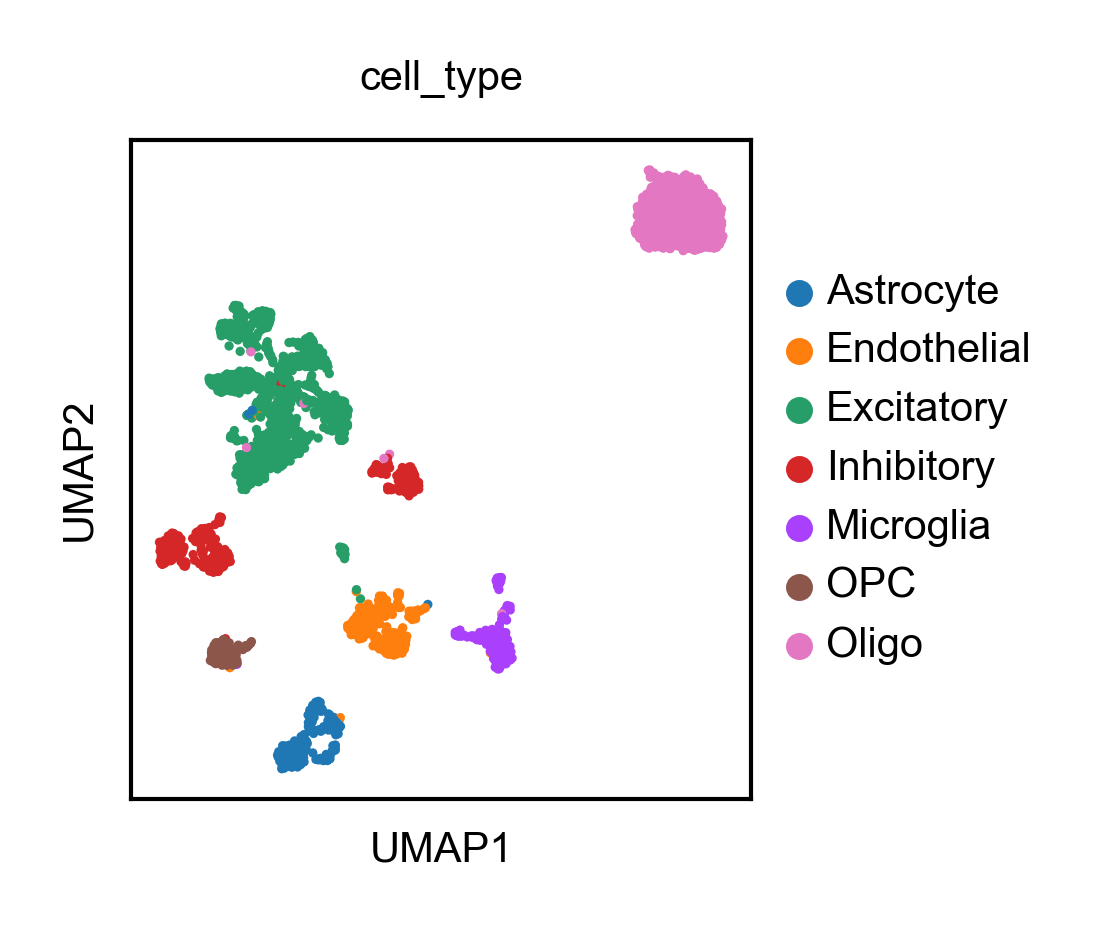

In [129]:
sc.pp.highly_variable_genes(slide, flavor="seurat_v3", n_top_genes=2000)
slide = slide[:, slide.var.highly_variable]
sc.tl.pca(slide, svd_solver="arpack")
sc.pp.neighbors(slide, n_neighbors=10, n_pcs=40)
sc.tl.umap(slide)

import matplotlib as mpl
mpl.rcParams['axes.linewidth'] = 0.5
plt.rcParams["figure.figsize"] = (1.8, 1.5)
fig = sc.pl.umap(slide, color="cell_type", legend_fontsize=5, show=False, return_fig=True, size=5)
ax = fig.axes[0]
leg = ax.get_legend()
for h in leg.legend_handles:
    h.set_sizes([5])
fig.tight_layout()
fig.show()

In [130]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

X = slide.obsm['X_umap']
labels = slide.obs['cell_type'].astype('category').cat.codes

sil_score = silhouette_score(X, labels)
db_index = davies_bouldin_score(X, labels)
print(f"Davies-Bouldin Index: {db_index:.4f}")
print(f"Silhouette Score: {sil_score:.4f}")

from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=slide.obs['cell_type'].nunique(), random_state=0)
cluster_labels = kmeans.fit_predict(X)

from sklearn.metrics.cluster import contingency_matrix
def purity_score(y_true, y_pred):
    contingency = contingency_matrix(y_true, y_pred)
    return np.sum(np.amax(contingency, axis=0)) / np.sum(contingency)

purity = purity_score(slide.obs['cell_type'].astype('category').cat.codes, cluster_labels)
print(f"Purity Score: {purity:.4f}")

Davies-Bouldin Index: 0.8358
Silhouette Score: 0.6516
Purity Score: 0.9152


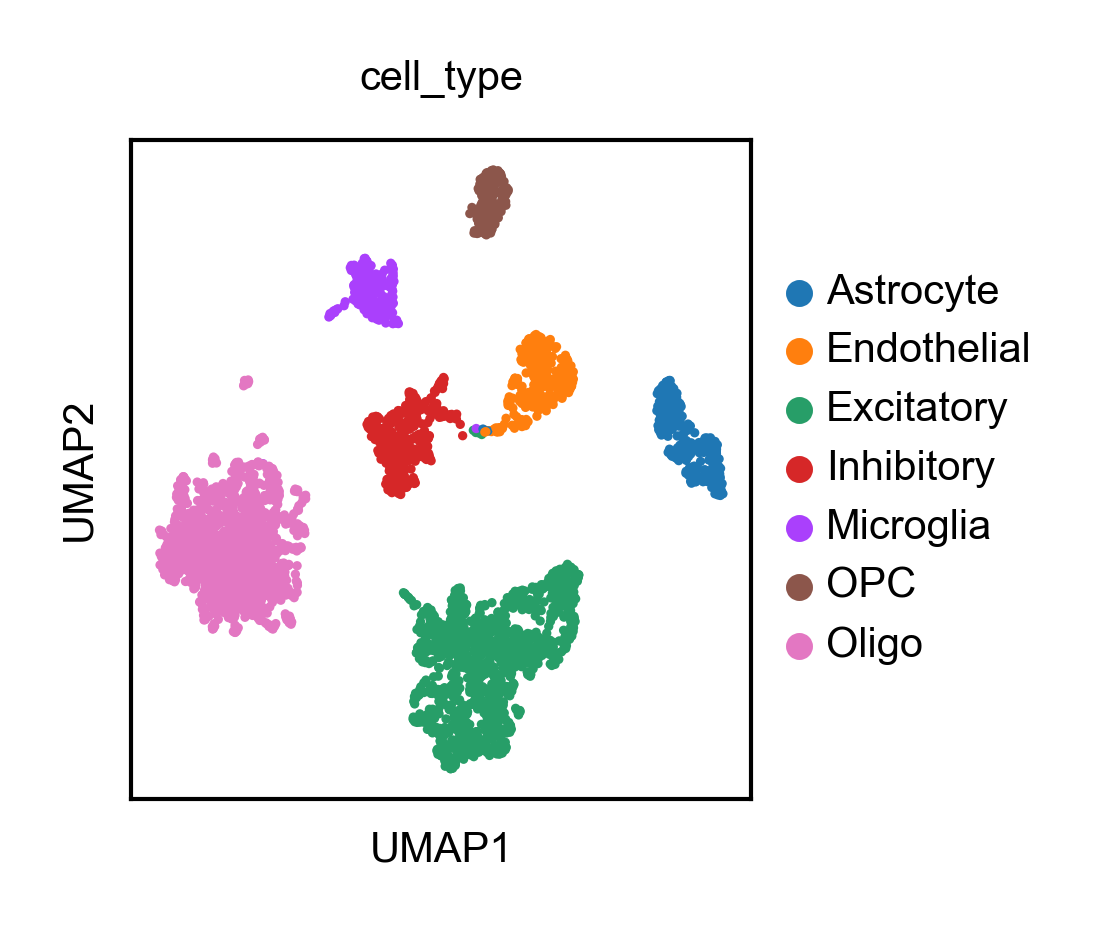

In [131]:
adata = adata_denoised.copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, flavor="seurat_v3", n_top_genes=2000)
adata = adata[:, adata.var.highly_variable]
sc.tl.pca(adata, svd_solver="arpack")
sc.pp.neighbors(adata, n_neighbors=10, n_pcs=40)
sc.tl.umap(adata)

import matplotlib as mpl
mpl.rcParams['axes.linewidth'] = 0.5
plt.rcParams["figure.figsize"] = (1.8, 1.5)
fig = sc.pl.umap(adata, color="cell_type", legend_fontsize=5, show=False, return_fig=True, size=5)
ax = fig.axes[0]
leg = ax.get_legend()
for h in leg.legend_handles:
    h.set_sizes([5])
fig.tight_layout()
fig.show()

In [132]:
X = adata.obsm['X_umap']
labels = adata.obs['cell_type'].astype('category').cat.codes

sil_score = silhouette_score(X, labels)
db_index = davies_bouldin_score(X, labels)
print(f"Davies-Bouldin Index of enhanced: {db_index:.4f}")
print(f"Silhouette Score of enhanced: {sil_score:.4f}")

kmeans = KMeans(n_clusters=adata.obs['cell_type'].nunique(), random_state=0)
cluster_labels = kmeans.fit_predict(X)
purity = purity_score(adata.obs['cell_type'].astype('category').cat.codes, cluster_labels)
print(f"Purity Score of enhanced: {purity:.4f}")

Davies-Bouldin Index of enhanced: 0.3795
Silhouette Score of enhanced: 0.6717
Purity Score of enhanced: 0.9572


## 7. Marker genes visualization

We compare the expression of cell-type marker genes before and after denoising, and the results from the scRNA-seq data.

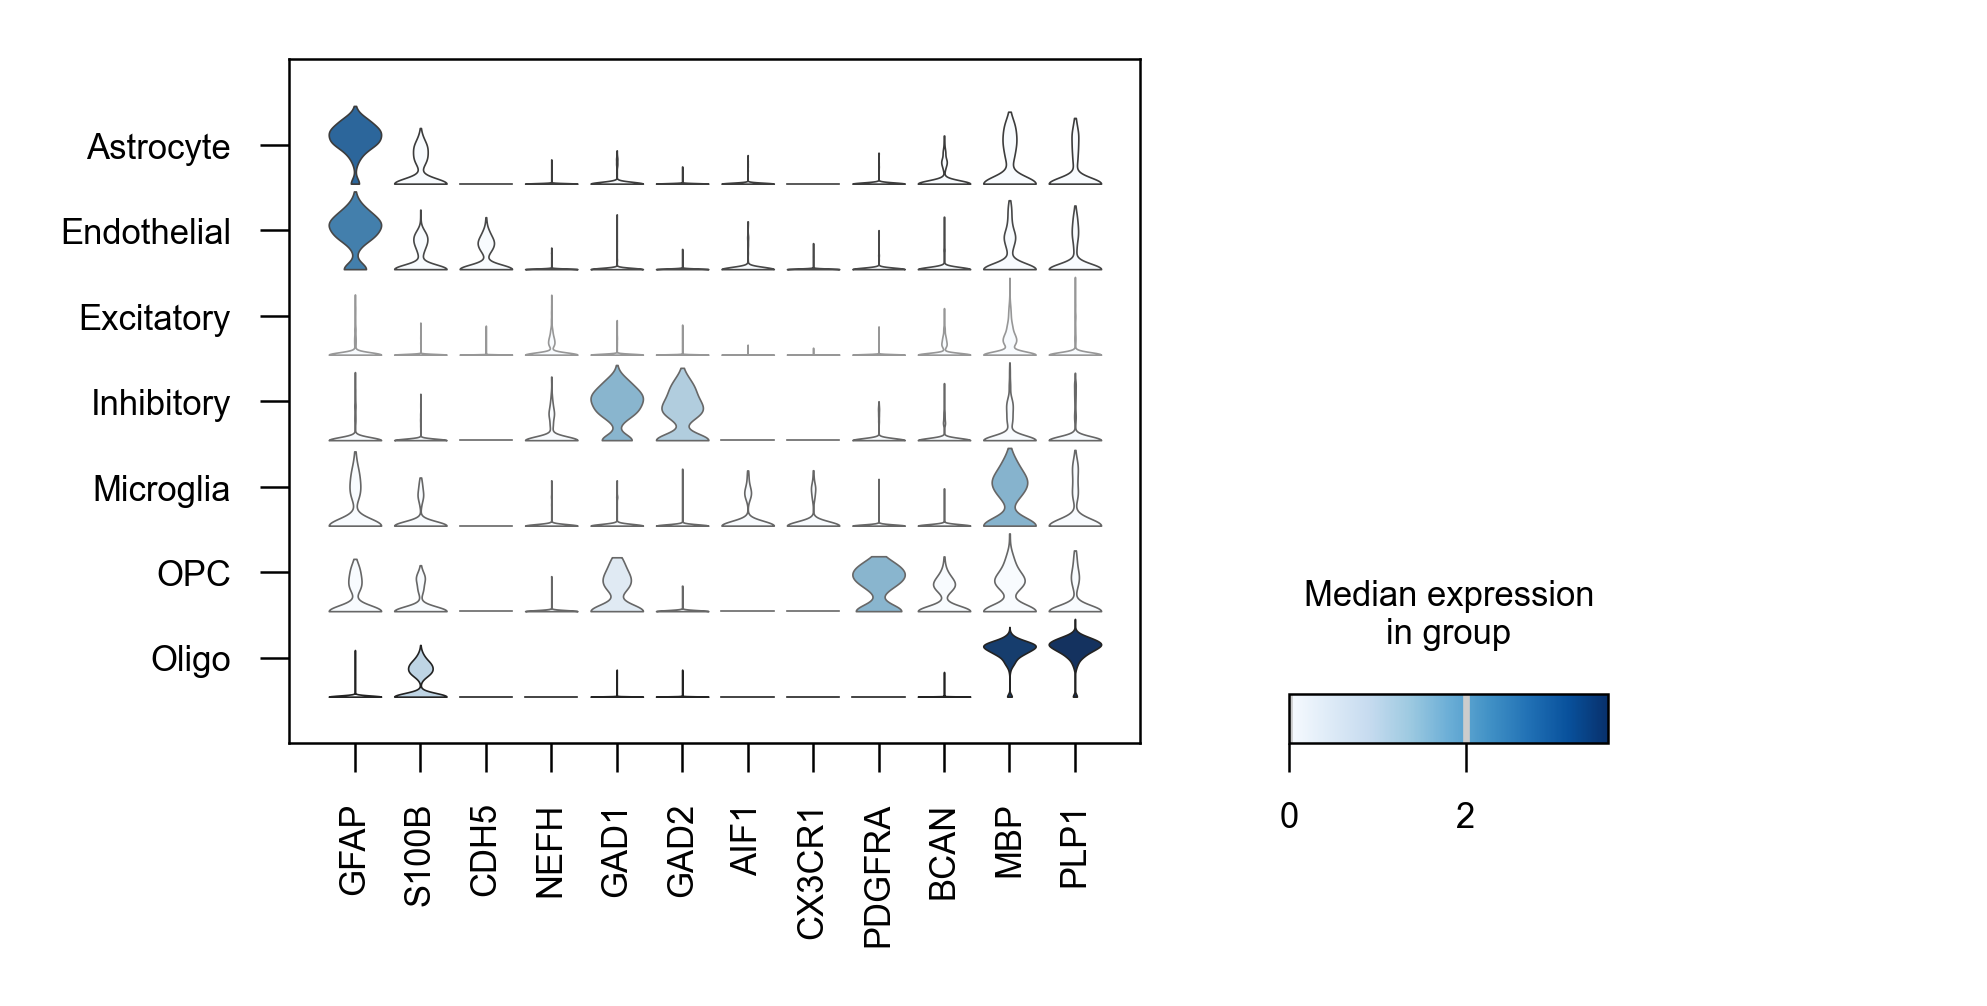

In [133]:
slide = sc.read_h5ad(data_dir / "slide_tag.h5ad")
singlecell = sc.read_h5ad(data_dir / "sc_seq.h5ad")
slide.var_names_make_unique()
singlecell.var_names_make_unique()

common_gene = slide.var_names.intersection(singlecell.var_names)
slide = slide[:, common_gene]
singlecell = singlecell[:, common_gene]

marker_genes = [
    *["GFAP", "S100B"],
    *["CDH5"],
    *["NEFH"],
    *["GAD1", "GAD2"],
    *["AIF1", "CX3CR1"],
    *["PDGFRA", "BCAN"],
    *["MBP", "PLP1"],
]

#Since the Slide-tags data has been normalized, we just normalize scRNA-seq data.
#Slide-tags data before denoising
import matplotlib as mpl
mpl.rcParams['axes.linewidth'] = 0.3
sc.pl.stacked_violin(slide, marker_genes, groupby="cell_type", figsize=(3.5, 1.5), show=False)
fig = plt.gcf()
cax = fig.axes[-1]
pos = cax.get_position()
cax.set_position([pos.x0, pos.y0, pos.width * 0.5, pos.height])
for ax in plt.gcf().axes:
    ax.tick_params(axis='y', width=0.3)
    ax.tick_params(axis='x', width=0.3)
fig.tight_layout()
fig.show()

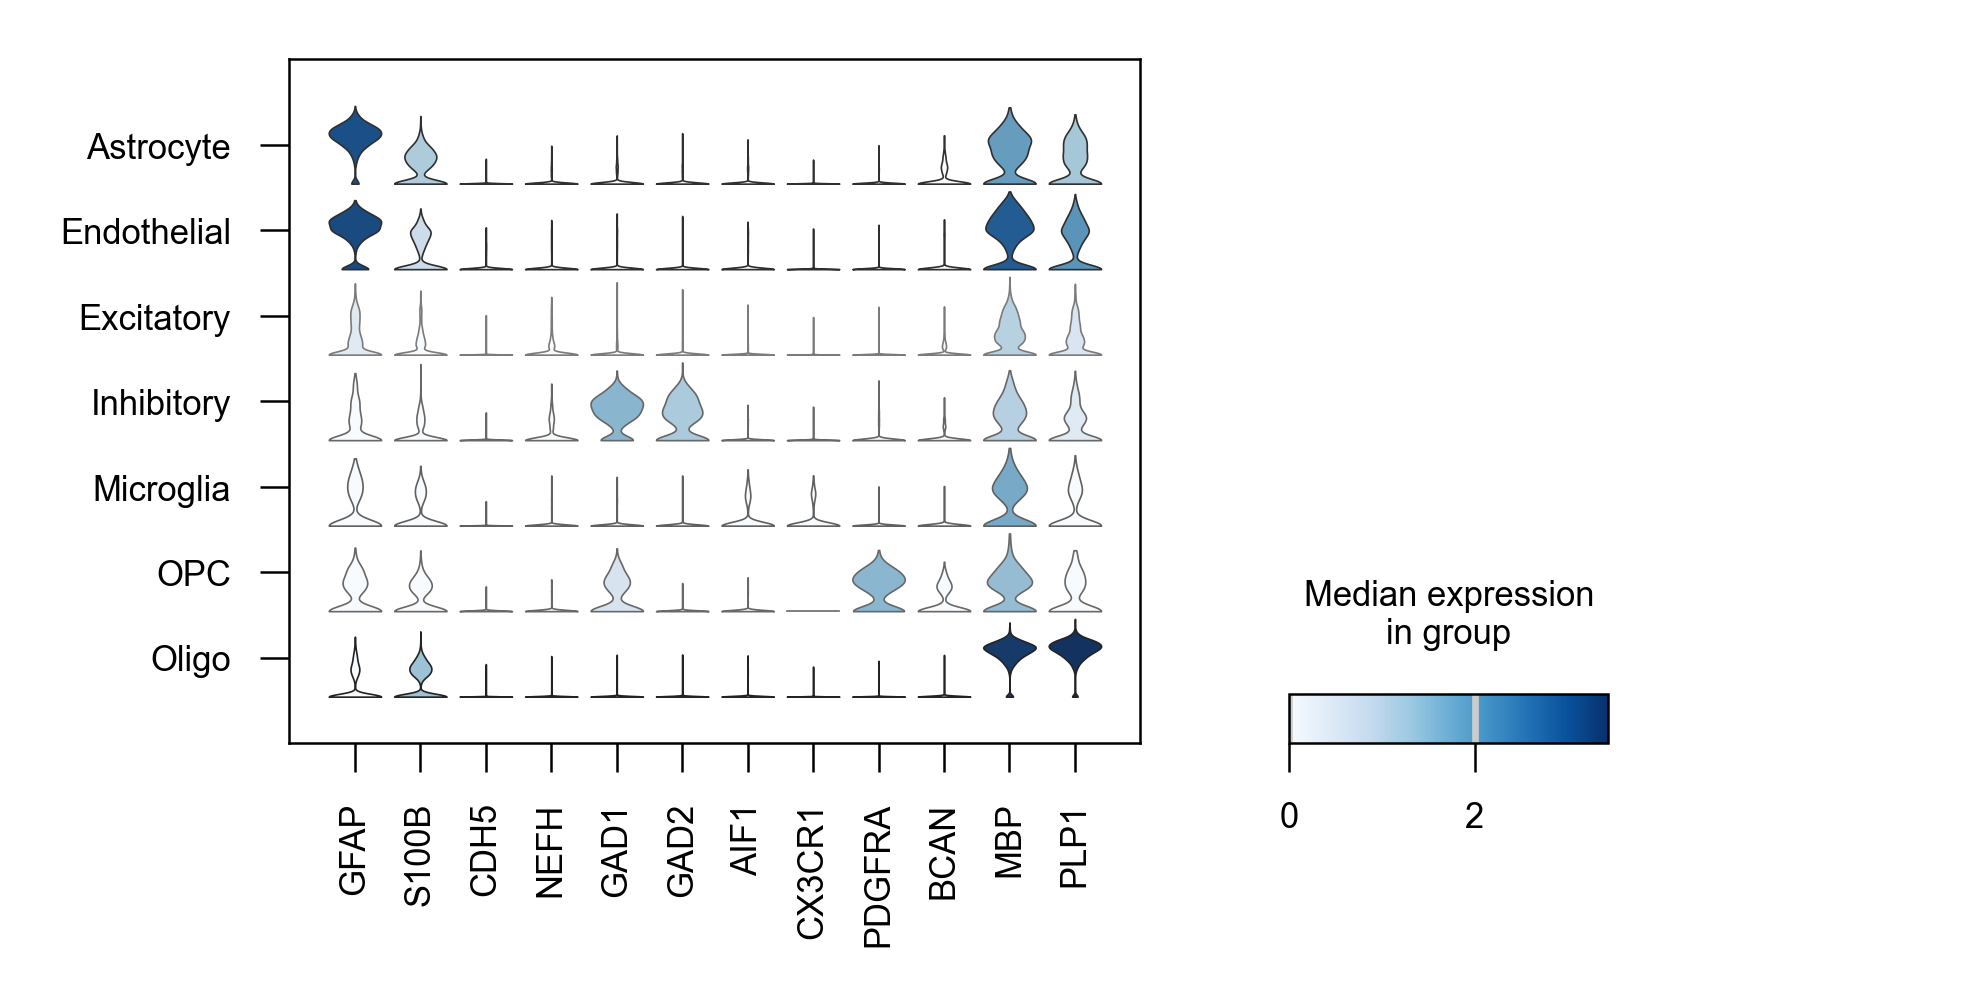

In [134]:
#scRNA-seq data
sc.pp.normalize_total(singlecell, target_sum=1e4)
sc.pp.log1p(singlecell)

import matplotlib as mpl
mpl.rcParams['axes.linewidth'] = 0.3
sc.pl.stacked_violin(singlecell, marker_genes, groupby="cell_type", figsize=(3.5, 1.5), show=False)
fig = plt.gcf()
cax = fig.axes[-1]
pos = cax.get_position()
cax.set_position([pos.x0, pos.y0, pos.width * 0.5, pos.height])
for ax in plt.gcf().axes:
    ax.tick_params(axis='y', width=0.3)
    ax.tick_params(axis='x', width=0.3)
fig.tight_layout()
fig.show()

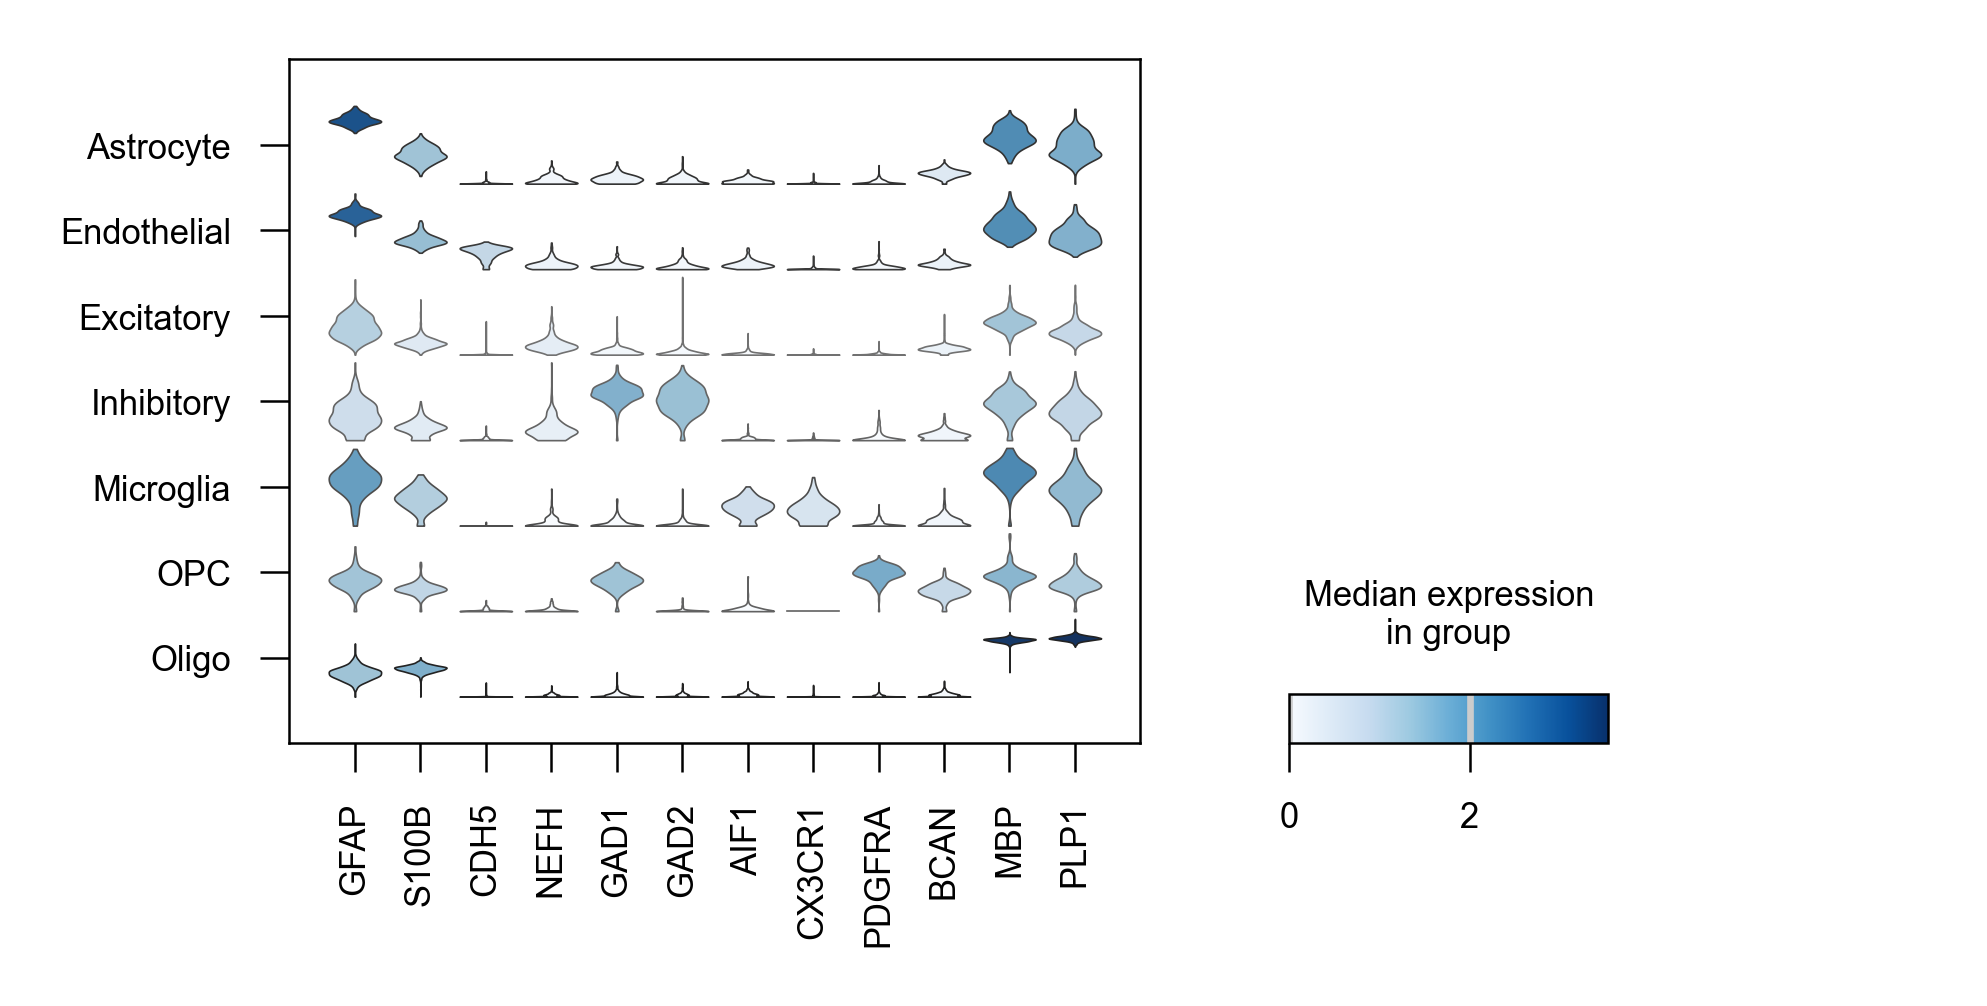

In [135]:
#Slide-tags data after denoising
adata = adata_denoised.copy()
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)

import matplotlib as mpl
mpl.rcParams['axes.linewidth'] = 0.3
sc.pl.stacked_violin(adata, marker_genes, groupby="cell_type", figsize=(3.5, 1.5), show=False)
fig = plt.gcf()
cax = fig.axes[-1]
pos = cax.get_position()
cax.set_position([pos.x0, pos.y0, pos.width * 0.5, pos.height])
for ax in plt.gcf().axes:
    ax.tick_params(axis='y', width=0.3)
    ax.tick_params(axis='x', width=0.3)
fig.tight_layout()
fig.show()